# Online Crew — Phase I (AI-aided pair): How does LLaVA behave?

**Task:** Why do large vision-language models hallucinate objects that are not in the image?
**Model:** [LLaVA-1.5-7B](https://llava-vl.github.io/) (`llava-hf/llava-1.5-7b-hf`), treated as a **black box** (only inputs and outputs).
**Data:** [POPE](https://github.com/RUCAIBox/POPE) (`lmms-lab/POPE`): 500 COCO val2014 images, 9,000 yes/no questions *"Is there a {object} in the image?"*, in 3 splits:
- **random**: absent objects chosen at random
- **popular**: absent objects that are frequent in COCO
- **adversarial**: absent objects that often *co-occur* with what is in the image

Plus **COCO 2014 annotations** (object counts, sizes, co-occurrence statistics) as context for the hypotheses.

**Pair:** AI-aided pair in Phase I (code written with GenAI support; see `ai-interactions/`).

### Questions we investigate
1. How often does LLaVA say *yes* to absent objects, and in which split?
2. **Which** objects get hallucinated?
3. **Why**: is it driven by object frequency, by co-occurrence with objects that *are* present, or by scene clutter?
4. **How confident** is the model when it hallucinates?
5. Which **kinds of images** (regions of a 2D image map) produce most hallucinations, and what distinguishes them?
6. In free-form captions, **where** in the text do hallucinations appear?

> Runtime: **GPU (T4 is enough)**. Runtime → Change runtime type → T4 GPU. Full run ≈ 45–70 min; results are checkpointed to Google Drive, so a disconnect does not lose progress (just re-run all cells).

## 0. Setup

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip -q install -U transformers accelerate bitsandbytes datasets umap-learn plotly kaleido==0.2.1

name, memory.total [MiB]
Tesla T4, 15360 MiB
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
# ---------------- CONFIG ----------------
MODEL_ID     = "llava-hf/llava-1.5-7b-hf"
N_IMAGES     = None     # None = all 500 images. Use e.g. 10 for a quick test run first.
BATCH        = 6        # questions per forward pass (lower to 3 if you get CUDA out-of-memory)
RUN_CAPTIONS = True     # free-form caption experiment (section 10)
N_CAPTIONS   = 100      # images to caption
USE_DRIVE    = True     # checkpoint results to Google Drive
SEED         = 0
# -----------------------------------------
import os, re, json, math, random, zipfile, urllib.request, collections
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
import plotly.express as px, plotly.graph_objects as go
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = "/content/drive/MyDrive/aivis_phase1"
else:
    OUT = "/content/aivis_phase1"
FIG = f"{OUT}/figures"
os.makedirs(FIG, exist_ok=True)
SUMMARY = {}   # key numbers collected for the report / video

def save_fig(fig, name):
    # plotly -> interactive HTML + static PNG; matplotlib -> PNG
    if isinstance(fig, go.Figure):
        fig.write_html(f"{FIG}/{name}.html")
        try: fig.write_image(f"{FIG}/{name}.png", scale=2, width=1000, height=600)
        except Exception as e: print("PNG export skipped:", e)
    else:
        fig.savefig(f"{FIG}/{name}.png", dpi=160, bbox_inches="tight")
print("Outputs ->", OUT)

Mounted at /content/drive
Outputs -> /content/drive/MyDrive/aivis_phase1


## 1. Load POPE

In [3]:
from datasets import load_dataset
ds = load_dataset("lmms-lab/POPE", split="test")
meta = ds.remove_columns(["image"]).to_pandas()
# robust parsing: tolerate "a"/"an"/no article, extra spaces, case, typos after "in the"
meta["object"] = (meta["question"].str.extract(r"(?i)there\s+(?:is\s+)?(?:an?\s+)?(.+?)\s+in\s+the", expand=False)
                    .str.strip().str.lower())
bad = meta[meta["object"].isna()]
print("questions that could not be parsed:", len(bad)); display(bad.question.drop_duplicates().head(10))
meta = meta.dropna(subset=["object"])
meta["image_id"] = meta["image_source"].str.split("_").str[-1].astype(int)
print("distinct objects:", meta.object.nunique())

# one PIL image per COCO image (the 9,000 questions share 500 images)
first_idx = meta.groupby("image_source").head(1).index.tolist()
images = {meta.loc[i, "image_source"]: ds[int(i)]["image"].convert("RGB") for i in first_idx}

sources = sorted(images)
if N_IMAGES: sources = sources[:N_IMAGES]
meta = meta[meta.image_source.isin(sources)].reset_index(drop=True)
print(meta.shape, "questions on", len(sources), "images")
print(meta.groupby(["category", "answer"]).size().unstack())
meta.head()

README.md:   0%|          | 0.00/2.16k [00:00<?, ?B/s]

data/test-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B / 85.0MB            

data/test-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B / 85.0MB            

data/test-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/test-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B / 85.0MB            

... (2 outputs left out)

questions that could not be parsed: 0


,question


distinct objects: 79
(9000, 8) questions on 500 images
answer         no   yes
category               
adversarial  1500  1500
popular      1500  1500
random       1500  1500


,id,question_id,question,answer,image_source,category,object,image_id
0,0,1,Is there a snowboard in the image?,yes,COCO_val2014_000000310196,adversarial,snowboard,310196
1,1,2,Is there a backpack in the image?,no,COCO_val2014_000000310196,adversarial,backpack,310196
2,2,3,Is there a person in the image?,yes,COCO_val2014_000000310196,adversarial,person,310196
3,3,4,Is there a car in the image?,no,COCO_val2014_000000310196,adversarial,car,310196
4,4,5,Is there a skis in the image?,yes,COCO_val2014_000000310196,adversarial,skis,310196


## 2. Load LLaVA-1.5 (4-bit on small GPUs)

In [4]:
from transformers import AutoProcessor, LlavaForConditionalGeneration, BitsAndBytesConfig
vram = torch.cuda.get_device_properties(0).total_memory / 1e9
quant = vram < 30
kw = dict(device_map="auto", torch_dtype=torch.float16, low_cpu_mem_usage=True)
if quant:
    kw["quantization_config"] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16,
                                                   bnb_4bit_quant_type="nf4")
model = LlavaForConditionalGeneration.from_pretrained(MODEL_ID, **kw).eval()
processor = AutoProcessor.from_pretrained(MODEL_ID)
processor.tokenizer.padding_side = "left"   # so the last position is the answer position for every row
SUMMARY["model"] = MODEL_ID + (" (4-bit NF4)" if quant else " (fp16)")

tok = processor.tokenizer
def token_ids(words):
    ids = set()
    for w in words:
        for t in (w, "▁" + w):
            i = tok.convert_tokens_to_ids(t)
            if i is not None and i != tok.unk_token_id: ids.add(i)
        enc = tok.encode(w, add_special_tokens=False)
        if len(enc) == 1: ids.add(enc[0])
    return sorted(ids)
YES_IDS, NO_IDS = token_ids(["Yes", "yes", "YES"]), token_ids(["No", "no", "NO"])
print("yes ids", YES_IDS, tok.convert_ids_to_tokens(YES_IDS))
print("no ids ", NO_IDS,  tok.convert_ids_to_tokens(NO_IDS))

POPE_SUFFIX = "\nAnswer the question using a single word or phrase."   # LLaVA-1.5's own POPE prompt
def prompt(text):
    conv = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": text}]}]
    return processor.apply_chat_template(conv, add_generation_prompt=True)
print(prompt("Is there a dog in the image?" + POPE_SUFFIX))

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/70.1k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

... (7 outputs left out)

tokenizer.model: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/41.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/552 [00:00<?, ?B/s]

yes ids [3582, 3869, 4874, 8241, 21143, 22483] ['yes', '▁Yes', '▁yes', 'Yes', 'YES', '▁YES']
no ids  [694, 1217, 1939, 3782, 6632, 11698] ['▁no', 'no', '▁No', 'No', 'NO', '▁NO']
USER: <image>
Is there a dog in the image?
Answer the question using a single word or phrase. ASSISTANT:


In [5]:
def to_model(inp):
    inp = inp.to(model.device); inp["pixel_values"] = inp["pixel_values"].to(torch.float16); return inp

@torch.no_grad()
def answer_probs(img, questions):
    # One forward pass; read the next-token distribution at the answer position.
    texts = [prompt(q + POPE_SUFFIX) for q in questions]
    inp = to_model(processor(images=[img] * len(texts), text=texts, padding=True, return_tensors="pt"))
    logp = torch.log_softmax(model(**inp, use_cache=False).logits[:, -1, :].float(), dim=-1)
    ly, ln = torch.logsumexp(logp[:, YES_IDS], -1), torch.logsumexp(logp[:, NO_IDS], -1)
    p_yes = torch.sigmoid(ly - ln)                      # P(yes | yes-or-no)
    mass  = (ly.exp() + ln.exp())                       # how much probability is on yes/no at all
    top   = tok.convert_ids_to_tokens(logp.argmax(-1).tolist())
    return p_yes.cpu().numpy(), mass.cpu().numpy(), top

# sanity check on one image: compare with free generation
src = sources[0]; qs = meta[meta.image_source == src].question.tolist()[:4]
print(answer_probs(images[src], qs))
inp = to_model(processor(images=images[src], text=prompt(qs[0] + POPE_SUFFIX), return_tensors="pt"))
out = model.generate(**inp, max_new_tokens=5, do_sample=False)
print(qs[0], "->", processor.decode(out[0][inp["input_ids"].shape[1]:], skip_special_tokens=True))

(array([0.04535239, 0.0161527 , 0.9861513 , 0.665409  ], dtype=float32), array([0.9999479, 0.9999456, 0.999972 , 0.999912 ], dtype=float32), ['▁No', '▁No', '▁Yes', '▁Yes'])
Is there a truck in the image? -> No


## 3. Run all POPE questions (checkpointed, resumable)

In [6]:
from tqdm.auto import tqdm
CKPT = f"{OUT}/pope_llava_raw.csv"
done = pd.read_csv(CKPT) if os.path.exists(CKPT) else pd.DataFrame()
done_ids = set(done["id"].astype(str)) if len(done) else set()
rows = []
todo = [s for s in sources if not set(meta[meta.image_source == s]["id"].astype(str)) <= done_ids]
for k, src in enumerate(tqdm(todo)):
    sub = meta[meta.image_source == src]
    for i in range(0, len(sub), BATCH):
        chunk = sub.iloc[i:i + BATCH]
        p, m, t = answer_probs(images[src], chunk.question.tolist())
        for (_, r), pi, mi, ti in zip(chunk.iterrows(), p, m, t):
            rows.append({"id": str(r["id"]), "p_yes": float(pi), "yesno_mass": float(mi), "top_token": ti})
    if (k + 1) % 20 == 0 or k == len(todo) - 1:
        done = pd.concat([done, pd.DataFrame(rows)], ignore_index=True).drop_duplicates("id", keep="last")
        done.to_csv(CKPT, index=False); rows = []
print("answered:", len(done))

  0%|          | 0/500 [00:00<?, ?it/s]

answered: 9000


In [7]:
res = meta.assign(id=meta["id"].astype(str)).merge(done.assign(id=done["id"].astype(str)), on="id", how="inner")
res["pred"]    = np.where(res.p_yes > 0.5, "yes", "no")
res["present"] = res.answer == "yes"
res["hallucinated"] = (~res.present) & (res.pred == "yes")   # false 'yes' on an absent object
res["missed"]       = res.present & (res.pred == "no")       # false 'no' on a present object
print("mean prob mass on yes/no tokens:", res.yesno_mass.mean().round(3), "(close to 1 = clean answers)")
res.to_csv(f"{OUT}/pope_llava_results.csv", index=False)
res.head()

mean prob mass on yes/no tokens: 1.0 (close to 1 = clean answers)


,id,question_id,question,answer,image_source,category,object,image_id,p_yes,yesno_mass,top_token,pred,present,hallucinated,missed
0,0,1,Is there a snowboard in the image?,yes,COCO_val2014_000000310196,adversarial,snowboard,310196,0.835482,0.999920,▁Yes,yes,True,False,False
1,1,2,Is there a backpack in the image?,no,COCO_val2014_000000310196,adversarial,backpack,310196,0.019719,0.999958,▁No,no,False,False,False
2,2,3,Is there a person in the image?,yes,COCO_val2014_000000310196,adversarial,person,310196,0.903294,0.999960,▁Yes,yes,True,False,False
3,3,4,Is there a car in the image?,no,COCO_val2014_000000310196,adversarial,car,310196,0.007938,0.999965,▁No,no,False,False,False
4,4,5,Is there a skis in the image?,yes,COCO_val2014_000000310196,adversarial,skis,310196,0.752010,0.999885,▁Yes,yes,True,False,False


## 4. COCO context: objects per image, object sizes, co-occurrence
We use COCO **val2014** annotations for the 500 test images (what is really there, how big, how cluttered)
and COCO **train2014** annotations to measure how often objects co-occur, i.e. the kind of statistics LLaVA was exposed to during training.

In [8]:
ANN = "/content/coco_ann"
if not os.path.exists(f"{ANN}/annotations/instances_val2014.json"):
    os.makedirs(ANN, exist_ok=True)
    urllib.request.urlretrieve("http://images.cocodataset.org/annotations/annotations_trainval2014.zip", f"{ANN}/a.zip")
    with zipfile.ZipFile(f"{ANN}/a.zip") as z:
        for n in ["annotations/instances_val2014.json", "annotations/instances_train2014.json"]: z.extract(n, ANN)

val = json.load(open(f"{ANN}/annotations/instances_val2014.json"))
cats = {c["id"]: c["name"] for c in val["categories"]}
supercat = {c["name"]: c["supercategory"] for c in val["categories"]}
wh = {im["id"]: im["width"] * im["height"] for im in val["images"]}
ids_needed = set(res.image_id)

img_objs = collections.defaultdict(list)        # image_id -> list of (category, area fraction)
for a in val["annotations"]:
    if a["image_id"] in ids_needed:
        img_objs[a["image_id"]].append((cats[a["category_id"]], a["area"] / wh[a["image_id"]]))
del val

img_meta = pd.DataFrame([{"image_id": i,
                          "n_instances": len(img_objs[i]),
                          "n_categories": len({c for c, _ in img_objs[i]}),
                          "present_set": sorted({c for c, _ in img_objs[i]})} for i in ids_needed]).set_index("image_id")
obj_area = collections.defaultdict(float)       # (image_id, category) -> total area fraction
for i, lst in img_objs.items():
    for c, a in lst: obj_area[(i, c)] += a

train = json.load(open(f"{ANN}/annotations/instances_train2014.json"))
per_img = collections.defaultdict(set)
for a in train["annotations"]: per_img[a["image_id"]].add(cats[a["category_id"]])
n_train = len(train["images"]); del train
names = sorted(supercat)
cnt = pd.Series(0, index=names, dtype=float)
co  = pd.DataFrame(0.0, index=names, columns=names)
for s in per_img.values():
    s = list(s); cnt[s] += 1; co.loc[s, s] += 1
cat_freq  = cnt / n_train                       # P(object appears in a training image)
cooc_cond = co.div(cnt, axis=0)                 # cooc_cond.loc[a, b] = P(b present | a present)
print("POPE objects missing from COCO names:", set(res.object) - set(names))

POPE objects missing from COCO names: set()


In [9]:
def cooc_score(row):
    # strongest 'pull' towards the queried object from anything actually in the image
    pres = [p for p in img_meta.loc[row.image_id, "present_set"] if p != row.object]
    return float(cooc_cond.loc[pres, row.object].max()) if pres and row.object in cooc_cond.columns else 0.0

res["cooc"]        = res.apply(cooc_score, axis=1)
res["obj_freq"]    = res.object.map(cat_freq)
res["supercat"]    = res.object.map(supercat)
res["n_instances"] = res.image_id.map(img_meta.n_instances)
res["n_categories"]= res.image_id.map(img_meta.n_categories)
res["obj_area"]    = [obj_area.get((i, o), 0.0) for i, o in zip(res.image_id, res.object)]
res.to_csv(f"{OUT}/pope_llava_results.csv", index=False)

## 5. Overview: how often does LLaVA say *yes* to absent objects?

In [10]:
def metrics(d):
    tp = ((d.pred == "yes") & d.present).sum(); fp = d.hallucinated.sum()
    fn = d.missed.sum(); tn = ((d.pred == "no") & ~d.present).sum()
    return pd.Series({"accuracy": (tp + tn) / len(d), "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1),
                      "F1": 2 * tp / max(2 * tp + fp + fn, 1), "yes_ratio": (d.pred == "yes").mean(),
                      "hallucination_rate": fp / max(fp + tn, 1), "miss_rate": fn / max(fn + tp, 1)})
order = ["random", "popular", "adversarial"]
tab = res.groupby("category").apply(metrics).loc[order].round(3)
SUMMARY["metrics_by_split"] = tab.to_dict(orient="index")
display(tab)

fig = px.bar(tab.reset_index().melt(id_vars="category", value_vars=["hallucination_rate", "miss_rate"]),
             x="category", y="value", color="variable", barmode="group", text_auto=".1%",
             title="Errors by POPE split: false 'yes' on absent objects vs. false 'no' on present objects",
             labels={"value": "rate", "category": "POPE split", "variable": ""})
fig.update_yaxes(tickformat=".0%"); fig.show(); save_fig(fig, "01_errors_by_split")

/tmp/ipykernel_3579/3457015754.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tab = res.groupby("category").apply(metrics).loc[order].round(3)


,accuracy,precision,recall,F1,yes_ratio,hallucination_rate,miss_rate
category,,,,,,,
random,0.877,0.971,0.777,0.863,0.400,0.023,0.223
popular,0.860,0.931,0.778,0.848,0.418,0.057,0.222
adversarial,0.838,0.884,0.777,0.827,0.440,0.102,0.223


PNG export skipped: 
Image export requires the Kaleido package, v1.0.0 or greater,
which can be installed using pip:

    $ pip install --upgrade "kaleido>=1"



## 6. Which objects are hallucinated, and why?
### 6a. Hallucination rate per queried object
Only absent-object questions, objects with at least 10 questions.

In [11]:
neg = res[~res.present]
per_obj = (neg.groupby("object").agg(n=("hallucinated", "size"), hall_rate=("hallucinated", "mean"),
                                     freq=("obj_freq", "first"), supercat=("supercat", "first"),
                                     mean_cooc=("cooc", "mean"))
              .query("n >= 10").sort_values("hall_rate", ascending=False))
SUMMARY["top_hallucinated_objects"] = per_obj.head(10)[["n", "hall_rate"]].round(3).to_dict(orient="index")
top = per_obj.head(25).reset_index()
fig = px.bar(top, x="object", y="hall_rate", color="supercat", hover_data=["n", "freq", "mean_cooc"],
             title="Objects LLaVA most often claims to see when they are absent (top 25)",
             labels={"hall_rate": "hallucination rate", "supercat": "COCO supercategory"})
fig.update_yaxes(tickformat=".0%"); fig.update_xaxes(categoryorder="total descending")
fig.show(); save_fig(fig, "02_hallucination_by_object")

PNG export skipped: 
Image export requires the Kaleido package, v1.0.0 or greater,
which can be installed using pip:

    $ pip install --upgrade "kaleido>=1"



### 6b. Hypothesis: co-occurrence pulls the model towards absent objects
`cooc` = the highest P(queried object | an object that *is* in the image), from COCO train statistics.
If LLaVA relies on learned scene statistics instead of looking, hallucinations should rise with `cooc`.

In [12]:
neg = res[~res.present].copy()
bins = [0, .05, .1, .2, .3, .4, .5, .7, 1.0001]
neg["cooc_bin"] = pd.cut(neg.cooc, bins, include_lowest=True)
g = neg.groupby("cooc_bin", observed=True).agg(n=("hallucinated", "size"), rate=("hallucinated", "mean")).reset_index()
g["cooc_bin"] = g.cooc_bin.astype(str)
g["se"] = np.sqrt(g.rate * (1 - g.rate) / g.n)
fig = go.Figure(go.Scatter(x=g.cooc_bin, y=g.rate, mode="lines+markers+text",
                           text=[f"n={n}" for n in g.n], textposition="top center",
                           error_y=dict(type="data", array=1.96 * g.se)))
fig.update_layout(title="Hallucination rate rises with co-occurrence strength (95% CI)",
                  xaxis_title="max P(queried object | object present in image), COCO train",
                  yaxis_title="hallucination rate", yaxis_tickformat=".0%")
fig.show(); save_fig(fig, "03_cooccurrence_vs_hallucination")
lo, hi = neg[neg.cooc < .1].hallucinated.mean(), neg[neg.cooc >= .4].hallucinated.mean()
SUMMARY["hall_rate_cooc_low(<0.1)"], SUMMARY["hall_rate_cooc_high(>=0.4)"] = round(lo, 3), round(hi, 3)
print(f"cooc<0.1: {lo:.1%}   cooc>=0.4: {hi:.1%}")

# same curve per split: is the adversarial gap explained by co-occurrence?
gs = neg.groupby(["category", "cooc_bin"], observed=True).hallucinated.agg(["mean", "size"]).reset_index()
gs = gs[gs["size"] >= 15]; gs["cooc_bin"] = gs.cooc_bin.astype(str)
fig = px.line(gs, x="cooc_bin", y="mean", color="category", markers=True, hover_data=["size"],
              category_orders={"category": order},
              title="Per split: at equal co-occurrence, do the splits still differ?",
              labels={"mean": "hallucination rate", "cooc_bin": "co-occurrence bin"})
fig.update_yaxes(tickformat=".0%"); fig.show(); save_fig(fig, "04_cooccurrence_by_split")

PNG export skipped: 
Image export requires the Kaleido package, v1.0.0 or greater,
which can be installed using pip:

    $ pip install --upgrade "kaleido>=1"

cooc<0.1: 1.7%   cooc>=0.4: 11.1%


PNG export skipped: 
Image export requires the Kaleido package, v1.0.0 or greater,
which can be installed using pip:

    $ pip install --upgrade "kaleido>=1"



### 6c. Which present objects trigger which hallucinations?
Rows: object that **is** in the image. Columns: absent object LLaVA said *yes* to.
Cell = rate of hallucinating the column object when the row object is present (only pairs with ≥ 5 opportunities).

In [13]:
pairs = []
for r in neg.itertuples():
    for p in img_meta.loc[r.image_id, "present_set"]:
        pairs.append((p, r.object, r.hallucinated))
pairs = pd.DataFrame(pairs, columns=["present", "queried", "hall"])
pg = pairs.groupby(["present", "queried"]).hall.agg(["mean", "size"]).reset_index()
pg = pg[pg["size"] >= 5]
top_q = per_obj.head(15).index
top_p = pairs[pairs.hall].present.value_counts().head(15).index
mat = pg.pivot(index="present", columns="queried", values="mean").reindex(index=top_p, columns=top_q)
fig = px.imshow(mat, color_continuous_scale="Reds", zmin=0, zmax=1, text_auto=".0%", aspect="auto",
                title="Trigger map: present object (row) → hallucinated object (column)",
                labels={"color": "hallucination rate"})
fig.show(); save_fig(fig, "05_trigger_map")
SUMMARY["strongest_triggers"] = (pg.sort_values(["mean", "size"], ascending=False).query("size >= 8").head(10)
                                   .round(3).to_dict(orient="records"))

PNG export skipped: 
Image export requires the Kaleido package, v1.0.0 or greater,
which can be installed using pip:

    $ pip install --upgrade "kaleido>=1"



### 6d. Object frequency vs. co-occurrence: which explains more?
Each bubble is one queried object (absent-object questions). A simple logistic regression then compares both factors (+ clutter) on the same scale.

In [14]:
fig = px.scatter(per_obj.reset_index(), x="freq", y="hall_rate", size="n", color="mean_cooc",
                 hover_name="object", log_x=True, color_continuous_scale="Viridis",
                 title="Per object: training frequency vs. hallucination rate (colour = mean co-occurrence)",
                 labels={"freq": "share of COCO train images containing the object (log)", "hall_rate": "hallucination rate"})
fig.update_yaxes(tickformat=".0%"); fig.show(); save_fig(fig, "06_frequency_vs_hallucination")

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
d = neg.dropna(subset=["cooc", "obj_freq", "n_instances"])
X = d[["cooc", "obj_freq", "n_instances"]].assign(obj_freq=np.log(d.obj_freq + 1e-4))
lr = LogisticRegression().fit(StandardScaler().fit_transform(X), d.hallucinated)
coef = pd.Series(lr.coef_[0], index=["co-occurrence", "log object frequency", "objects in image"]).round(3)
SUMMARY["logreg_standardized_coefs"] = coef.to_dict()
print("Standardized logistic-regression coefficients (bigger = stronger push towards hallucination):"); print(coef)

PNG export skipped: 
Image export requires the Kaleido package, v1.0.0 or greater,
which can be installed using pip:

    $ pip install --upgrade "kaleido>=1"

Standardized logistic-regression coefficients (bigger = stronger push towards hallucination):
co-occurrence           0.856
log object frequency   -0.545
objects in image        0.055
dtype: float64


## 7. Confidence: does LLaVA know when it is hallucinating?

In [15]:
res["outcome"] = np.select([res.present & (res.pred == "yes"), res.hallucinated, res.missed],
                           ["correct yes (present)", "HALLUCINATION (absent, said yes)", "miss (present, said no)"],
                           "correct no (absent)")
fig = px.histogram(res, x="p_yes", color="outcome", nbins=40, barmode="overlay", opacity=0.6, histnorm="percent",
                   title="P(yes) by outcome: hallucinations are often made with high confidence?",
                   labels={"p_yes": "model P(yes)"})
fig.show(); save_fig(fig, "07_confidence_by_outcome")
h = res[res.hallucinated]
SUMMARY["share_hallucinations_with_p_yes>0.9"] = round((h.p_yes > 0.9).mean(), 3)
SUMMARY["median_p_yes_hallucinations"] = round(h.p_yes.median(), 3)
SUMMARY["median_p_yes_correct_yes"] = round(res[res.present & (res.pred == 'yes')].p_yes.median(), 3)

# reliability diagram
res["conf_bin"] = pd.cut(res.p_yes, np.linspace(0, 1, 11), include_lowest=True)
cal = res.groupby("conf_bin", observed=True).agg(p=("p_yes", "mean"), actual=("present", "mean"), n=("present", "size")).reset_index()
fig = go.Figure([go.Scatter(x=[0, 1], y=[0, 1], mode="lines", line=dict(dash="dash", color="grey"), name="perfect calibration"),
                 go.Scatter(x=cal.p, y=cal.actual, mode="lines+markers", text=cal.n, name="LLaVA",
                            hovertemplate="mean P(yes)=%{x:.2f}<br>object present=%{y:.0%}<br>n=%{text}")])
fig.update_layout(title="Calibration: when LLaVA says P(yes)=x, how often is the object really there?",
                  xaxis_title="mean predicted P(yes)", yaxis_title="share of questions where object is present",
                  yaxis_tickformat=".0%")
fig.show(); save_fig(fig, "08_calibration")

PNG export skipped: 
Image export requires the Kaleido package, v1.0.0 or greater,
which can be installed using pip:

    $ pip install --upgrade "kaleido>=1"



PNG export skipped: 
Image export requires the Kaleido package, v1.0.0 or greater,
which can be installed using pip:

    $ pip install --upgrade "kaleido>=1"



## 8. Scene complexity and object size

In [16]:
neg = res[~res.present].copy(); pos = res[res.present].copy()
neg["clutter"] = pd.cut(neg.n_instances, [0, 2, 5, 10, 20, 1000], labels=["1–2", "3–5", "6–10", "11–20", ">20"])
a = neg.groupby("clutter", observed=True).hallucinated.agg(["mean", "size"]).reset_index()
pos["size_bin"] = pd.cut(pos.obj_area, [0, .005, .02, .05, .15, 1.01], labels=["<0.5%", "0.5–2%", "2–5%", "5–15%", ">15%"])
b = pos.groupby("size_bin", observed=True).missed.agg(["mean", "size"]).reset_index()

from plotly.subplots import make_subplots
fig = make_subplots(1, 2, subplot_titles=["Absent objects: hallucination vs. # objects in image",
                                          "Present objects: misses vs. object size (share of image)"])
fig.add_bar(x=a.clutter.astype(str), y=a["mean"], text=[f"n={n}" for n in a["size"]], row=1, col=1, name="hallucination")
fig.add_bar(x=b.size_bin.astype(str), y=b["mean"], text=[f"n={n}" for n in b["size"]], row=1, col=2, name="miss")
fig.update_yaxes(tickformat=".0%"); fig.update_layout(showlegend=False, title="Cluttered scenes and small objects")
fig.show(); save_fig(fig, "09_clutter_and_size")
SUMMARY["hall_rate_by_clutter"] = dict(zip(a.clutter.astype(str), a["mean"].round(3)))
SUMMARY["miss_rate_by_size"] = dict(zip(b.size_bin.astype(str), b["mean"].round(3)))

PNG export skipped: 
Image export requires the Kaleido package, v1.0.0 or greater,
which can be installed using pip:

    $ pip install --upgrade "kaleido>=1"



## 9. Image map: which kinds of scenes produce hallucinations?
We embed the 500 images with CLIP (an *independent* image encoder, so we stay outside LLaVA), project them to 2D with UMAP,
and colour each image by how many absent objects LLaVA claimed to see. Then we cluster the map and drill into the worst cluster.
**Hover over points** to see present and hallucinated objects.

In [17]:
from transformers import CLIPModel, CLIPProcessor
clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to("cuda").eval()
cproc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
with torch.no_grad():
    embs = []
    for i in range(0, len(sources), 32):
        inp = cproc(images=[images[s] for s in sources[i:i + 32]], return_tensors="pt").to("cuda")
        e = clip.visual_projection(clip.vision_model(pixel_values=inp["pixel_values"]).pooler_output)
        embs.append((e / e.norm(dim=-1, keepdim=True)).cpu().numpy())
emb = np.concatenate(embs)

import umap
from sklearn.cluster import KMeans
xy = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=SEED).fit_transform(emb)
K = 8
cl = KMeans(K, n_init=10, random_state=SEED).fit_predict(emb)
per_img = res[~res.present].groupby("image_source").hallucinated.sum().rename("n_hall").to_frame()
per_img["hallucinated"] = res[res.hallucinated].groupby("image_source").object.apply(lambda s: ", ".join(sorted(set(s))))
per_img["hallucinated"] = per_img["hallucinated"].fillna("–")
imap = pd.DataFrame({"image_source": sources, "x": xy[:, 0], "y": xy[:, 1], "cluster": cl.astype(str)}).join(per_img, on="image_source")
imap["image_id"] = imap.image_source.str.split("_").str[-1].astype(int)
imap["present"] = imap.image_id.map(lambda i: ", ".join(img_meta.loc[i, "present_set"]))
imap["n_instances"] = imap.image_id.map(img_meta.n_instances)
imap.to_csv(f"{OUT}/image_map.csv", index=False)

fig = px.scatter(imap, x="x", y="y", color="n_hall", symbol="cluster", color_continuous_scale="Reds",
                 hover_data={"image_source": True, "present": True, "hallucinated": True, "x": False, "y": False},
                 title="CLIP image map (UMAP): colour = # absent objects LLaVA said yes to (of 9 questions/image)")
fig.update_traces(marker=dict(size=9, line=dict(width=.5, color="black"))); fig.show(); save_fig(fig, "10_image_map")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


PNG export skipped: 
Image export requires the Kaleido package, v1.0.0 or greater,
which can be installed using pip:

    $ pip install --upgrade "kaleido>=1"



,images,mean_hall,mean_instances,typical_content,most_hallucinated
cluster,,,,,
1,80,0.78,12.12,"person, car, handbag, motorcycle, bicycle","truck, chair, car, handbag, backpack"
0,88,0.64,8.85,"person, cup, chair, dining table, bottle","dining table, chair, car, bottle, handbag"
2,71,0.61,8.42,"dining table, cup, person, bowl, pizza","bowl, dining table, cup, bottle, person"
4,48,0.52,7.69,"tv, person, laptop, keyboard, mouse","chair, bottle, tv, vase, car"
3,54,0.48,6.52,"chair, bed, vase, book, potted plant","cup, vase, book, chair, cell phone"
7,62,0.42,11.65,"person, car, truck, bus, traffic light","traffic light, truck, car, handbag, bicycle"
6,41,0.41,8.49,"person, sports ball, tennis racket, baseball b...","chair, cup, truck, car, baseball bat"
5,56,0.34,9.09,"person, skis, backpack, snowboard, surfboard","chair, skis, truck, skateboard, snowboard"


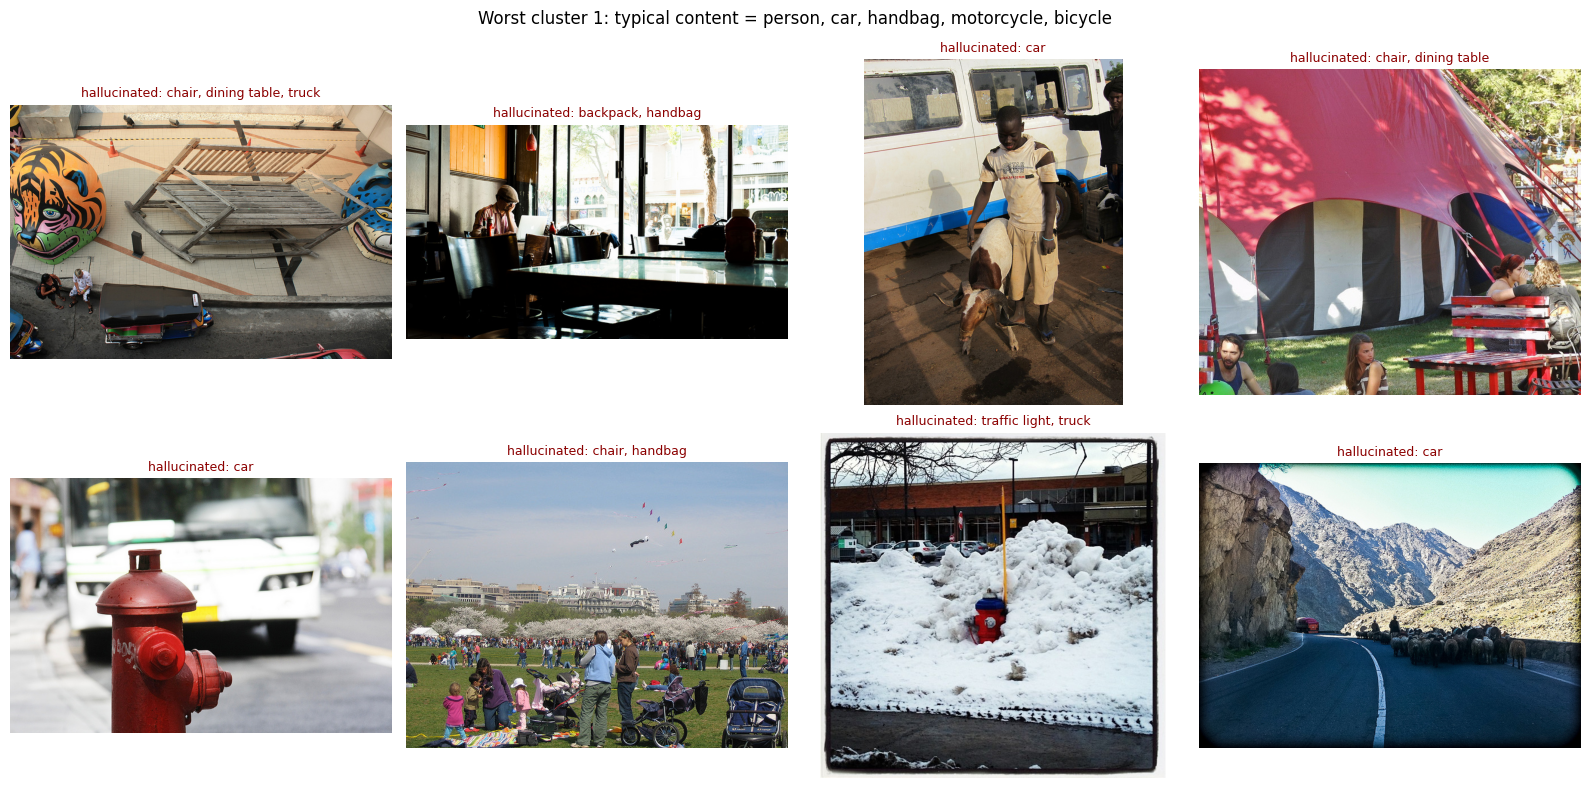

In [18]:
# cluster profile: what distinguishes high-hallucination clusters?
prof = imap.groupby("cluster").agg(images=("image_source", "size"), mean_hall=("n_hall", "mean"),
                                   mean_instances=("n_instances", "mean")).sort_values("mean_hall", ascending=False)
def top_items(col, c, k=5):
    s = imap[imap.cluster == c][col].str.split(", ").explode()
    return ", ".join(s[s != "–"].value_counts().head(k).index)
prof["typical_content"] = [top_items("present", c) for c in prof.index]
prof["most_hallucinated"] = [top_items("hallucinated", c) for c in prof.index]
display(prof.round(2))
SUMMARY["cluster_profile"] = prof.round(2).reset_index().to_dict(orient="records")

worst = prof.index[0]
ex = imap[imap.cluster == worst].sort_values("n_hall", ascending=False).head(8)
fig, axs = plt.subplots(2, 4, figsize=(16, 8))
for ax, r in zip(axs.flat, ex.itertuples()):
    ax.imshow(images[r.image_source]); ax.axis("off")
    ax.set_title(f"hallucinated: {r.hallucinated}"[:60], fontsize=9, color="darkred")
fig.suptitle(f"Worst cluster {worst}: typical content = {prof.loc[worst, 'typical_content']}")
plt.tight_layout(); plt.show(); save_fig(fig, "11_worst_cluster_examples")

## 10. Free-form captions: where do hallucinations appear in the text?
Yes/no probing is a constrained setting. Here LLaVA describes images freely; we mark every COCO object it mentions as
**grounded** (annotated in the image) or **hallucinated** (not annotated), CHAIR-style, and look at *where* in the caption each mention occurs.
*Limitation:* simple word matching with a small synonym list, so a few mentions may be mis-labelled.

In [19]:
SYN = {"person": ["person", "people", "man", "men", "woman", "women", "boy", "girl", "child", "children", "player", "kid", "kids"],
       "tv": ["tv", "television"], "dining table": ["dining table", "table"], "couch": ["couch", "sofa"],
       "cell phone": ["cell phone", "phone", "cellphone"], "motorcycle": ["motorcycle", "motorbike"],
       "airplane": ["airplane", "plane", "aircraft"], "bicycle": ["bicycle", "bike"], "car": ["car"],
       "laptop": ["laptop", "computer"], "potted plant": ["potted plant", "plant"], "sports ball": ["ball"],
       "hair drier": ["hair dryer", "hair drier"], "wine glass": ["wine glass"], "cup": ["cup", "mug"]}
patterns = {c: re.compile(r"\b(" + "|".join(re.escape(w) + r"(?:e?s)?" for w in SYN.get(c, [c])) + r")\b", re.I) for c in names}

def mentions(text):
    # each COCO category counted once per caption, at its first mention (relative position 0..1)
    found = {}
    for c, pat in patterns.items():
        m = pat.search(text)
        if m: found[c] = m.start() / max(len(text), 1)
    return sorted(found.items(), key=lambda t: t[1])

cap_rows = []
if RUN_CAPTIONS:
    for src in tqdm(sources[:N_CAPTIONS]):
        inp = to_model(processor(images=images[src], text=prompt("Describe this image in detail."), return_tensors="pt"))
        out = model.generate(**inp, max_new_tokens=200, do_sample=False)
        cap = processor.decode(out[0][inp["input_ids"].shape[1]:], skip_special_tokens=True).strip()
        iid = int(src.split("_")[-1]); present = set(img_meta.loc[iid, "present_set"])
        for c, pos in mentions(cap):
            cap_rows.append({"image_source": src, "object": c, "rel_pos": pos, "grounded": c in present, "caption": cap})
    caps = pd.DataFrame(cap_rows); caps.to_csv(f"{OUT}/captions_mentions.csv", index=False)
    chair_i = 1 - caps.grounded.mean()
    chair_s = caps.groupby("image_source").grounded.apply(lambda s: (~s).any()).mean()
    SUMMARY["CHAIR_i (hallucinated mentions / all mentions)"] = round(chair_i, 3)
    SUMMARY["CHAIR_s (captions with >=1 hallucination)"] = round(chair_s, 3)
    print(f"CHAIR_i={chair_i:.1%}  CHAIR_s={chair_s:.1%}")
    caps["where"] = pd.cut(caps.rel_pos, [0, .25, .5, .75, 1.01], labels=["1st quarter", "2nd", "3rd", "last quarter"], include_lowest=True)
    w = caps.groupby("where", observed=True).grounded.agg(lambda s: 1 - s.mean()).reset_index(name="hall_share")
    fig = px.bar(w, x="where", y="hall_share", text_auto=".0%",
                 title="Share of object mentions that are hallucinated, by position in the caption",
                 labels={"where": "position of the mention in the caption", "hall_share": "hallucinated share"})
    fig.update_yaxes(tickformat=".0%"); fig.show(); save_fig(fig, "12_caption_position")
    SUMMARY["caption_hall_share_by_position"] = dict(zip(w["where"].astype(str), w.hall_share.round(3)))
    display(caps[~caps.grounded][["image_source", "object", "caption"]].drop_duplicates("image_source").head(5))

  0%|          | 0/100 [00:00<?, ?it/s]

CHAIR_i=29.4%  CHAIR_s=67.0%


PNG export skipped: 
Image export requires the Kaleido package, v1.0.0 or greater,
which can be installed using pip:

    $ pip install --upgrade "kaleido>=1"



,image_source,object,caption
4,COCO_val2014_000000003845,knife,The image features a plate filled with a delic...
8,COCO_val2014_000000006033,cow,The image features a man standing next to a co...
13,COCO_val2014_000000007320,dining table,The image features a person holding a Nintendo...
17,COCO_val2014_000000007795,chair,The image showcases a cozy bedroom with two be...
24,COCO_val2014_000000008749,person,"The image features a large, freshly baked pizz..."


## Findings (full run: 500 images, 9,000 questions, LLaVA-1.5-7B 4-bit)

1. **Hallucination depends on *which* absent object is asked about.** LLaVA falsely says *yes* to 2.3% of absent objects in the *random* split, 5.7% in *popular*, and 10.2% in *adversarial*. The positive questions are identical in all splits, so the miss rate stays at 22%.
2. **Co-occurrence drives it.** The hallucination rate rises from **1.3%** when the queried object rarely co-occurs with anything in the image (max P ≤ 0.05) to about **15%** when it co-occurs often (0.3–0.7). At the same co-occurrence level the three splits behave similarly, so the adversarial split is hard *because* of co-occurrence. In a logistic regression, co-occurrence is the strongest factor (standardized coef. +0.86). Scene clutter has almost no effect (+0.06). Object frequency becomes negative (−0.55) once co-occurrence is controlled for.
3. **Two trigger blocks** (reordered trigger map). *Kitchen*: bowl, spoon, cup, bottle and fork trigger oven, bowl and cup (up to 40%). *Street*: car, truck and chair trigger handbag, truck, backpack and traffic light (car → truck 39%, truck → handbag 43%). LLaVA completes a typical scene rather than reporting what it sees.
4. **Hallucinations are hesitant, not confident.** Median P(yes) is **0.69** for hallucinations vs **0.93** for correct *yes* answers, and only 7% of hallucinations have P(yes) > 0.9. P(yes) separates them with AUROC 0.85. A 0.8 threshold would remove 78% of hallucinations, at the cost of 21% of correct *yes* answers.
5. **The more common error is missing small objects.** There are 1,001 misses vs 274 hallucinations. Objects covering < 0.5% of the image are missed 36% of the time, vs 4% for objects covering > 15%. LLaVA is conservative overall (yes-ratio 0.40–0.44).
6. **Image map:** the worst cluster is **busy street scenes** (people, cars, handbags, motorcycles; 0.78 hallucinations per image), while sports and snow scenes are lowest (0.34). The object *count* alone barely matters (finding 2), so it is the scene *type*, rich in co-occurring objects, that matters. Looking at the worst cluster's images shows that **some "hallucinations" are label gaps** in COCO: a distant car that is visible but not annotated, a picnic table counted as a dining table, and bench vs. chair (the strongest trigger, 48%). So the true hallucination rate is somewhat lower, and part of the co-occurrence effect is near-synonym confusion.
7. **Free-form captions hallucinate more, and late.** 67% of 100 detailed captions contain at least one object that is not in the image (CHAIR_s), and 29% of all object mentions are hallucinated (CHAIR_i). The hallucinated share rises from **13%** of mentions in the first quarter of a caption to **52%** in the last quarter. *Caveat:* word matching is approximate; for example, "table" is counted as COCO "dining table".

**Questions for Phase II (opening the black box):**
- Does LLaVA attend less to the image tokens later in a caption, when hallucinations rise? (attention to image vs. text tokens, over generation steps)
- Do co-occurrence hallucinations have weak visual evidence for the object? (saliency / relevance maps: hallucinated vs. correct *yes*)
- In which layer does *yes* win for absent objects? (logit lens across layers: kitchen and street blocks vs. random negatives)